In [1]:
from generate_repeater import generate_repeater_from_dist
import matplotlib.pyplot as plt
from zn2_stat import zn2_stat
import numpy as np
import scipy as sp
%load_ext autoreload
%autoreload 2

In [2]:
# Make the whole thing into a function:
# 

def distribution_testing(toas, colors, distribution, saving = False, title = "untitled"):
    dt = np.diff(toas)
    counts, bins, bars =  plt.hist(dt, bins = 100, weights=np.ones_like(dt) / len(dt))
    args = sp.stats.weibull_min.fit(dt)
    results = sp.stats.kstest(dt, 'weibull_min', args = args)

    # Set up plotting

    fig, ax = plt.subplots(1, 3)
    fig.set_figwidth(20)
    fig.set_figheight(5)

    # CDF fit

    ax[0].scatter(bins[:-1], np.cumsum(counts), color = colors[0], label = "generated data", linewidth = 2)
    ax[0].plot(bins[:-1], sp.stats.weibull_min.cdf(bins[:-1], c = args[0], loc = 0, scale = args[2]),
                                                    color = colors[1], linestyle = "--", label = f"fit p={round(results[1],3)}",
                                                    linewidth = 3.5)
    ax[0].set_xlabel("$\Delta$t[d]", fontsize = 15)
    ax[0].set_ylabel("Cumulative Probability", fontsize = 15)
    ax[0].tick_params(length = 5, width = 1, labelsize = 9)
    ax[0].legend(fontsize = 10)
    ax[0].set_title("CDF", fontsize = 15)
#    ax[0].set_yscale("log")
#    ax[0].set_xscale("log")


    # Histogram fit

    ax[1].hist(dt, bins = 100, color = colors[0], fill = True, alpha = 1, density = True, label = "generated data")
    ax[1].plot(bins, sp.stats.weibull_min.pdf(bins, c = args[0], loc = args[1], scale = args[2]), color = colors[1], linestyle = "--",
                                                label = f"fit p={round(results[1], 5)}\n shape = {round(args[0],3)}\n scale = {round(args[2],3)}", linewidth = 2)

    ax[1].set_xlabel("$\Delta$t[d]", fontsize = 20)
    ax[1].set_ylabel("#in bin ()", fontsize = 20)
    ax[1].tick_params(length = 5, width = 1, labelsize = 9)
    ax[1].legend(fontsize = 10)
    ax[1].set_title("wait time distribution", fontsize = 15)
    ax[1].set_yscale("log")
 #   ax[1].set_xscale("log")

    #Zn^2 plotting

    zn_sq, freqs, pvals = zn2_stat(False, 4, highest_freq = 0.20, plotting = True, saving = False, toa = toas)
    fig.suptitle(distribution, fontsize = 20)
    if saving:
        fig.savefig(f"D:\Thesis\\figures\\{title}", bbox_inches = "tight")

<class 'numpy.ndarray'>
[0.00110031 0.00974538 0.01964455 0.02901609 0.02937776 0.05591793
 0.05906468 0.06603348 0.07894829 0.08423553 0.08945492 0.10138027
 0.10292362 0.11335405 0.12246142 0.13487754 0.18556649 0.19502339
 0.19840055 0.22685945 0.23096999 0.245596   0.25031744 0.2520567
 0.25573809 0.25774537 0.28408218 0.30241989 0.30490247 0.32348375
 0.33492084 0.33717351 0.34575366 0.34923954 0.35287556 0.36778569
 0.37918708 0.38383266 0.39240293 0.39487145 0.40548589 0.41006379
 0.42321704 0.42903301 0.42954692 0.43000709 0.43039856 0.43046348
 0.43650594 0.45518047 0.46100141 0.46937689 0.47855981 0.48286821
 0.48575852 0.49454239 0.50229841 0.51147924 0.5401807  0.54139092
 0.55427362 0.56077205 0.56609277 0.57386277 0.58014475 0.6032398
 0.61289642 0.61721865 0.62975835 0.63429704 0.63928414 0.64038039
 0.64675229 0.65126302 0.65695184 0.66874572 0.67229406 0.67538231
 0.68068223 0.69366065 0.70282125 0.71029783 0.71526682 0.71741273
 0.71801638 0.76016405 0.79994929 0.8037

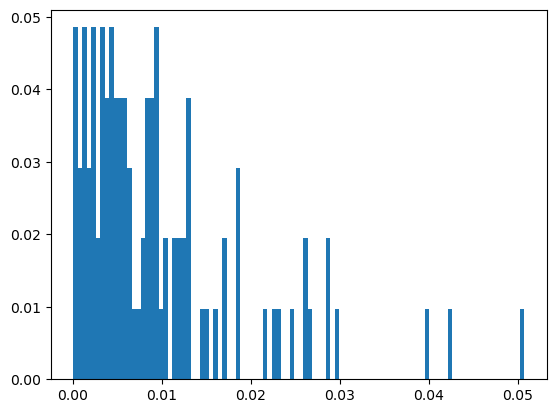

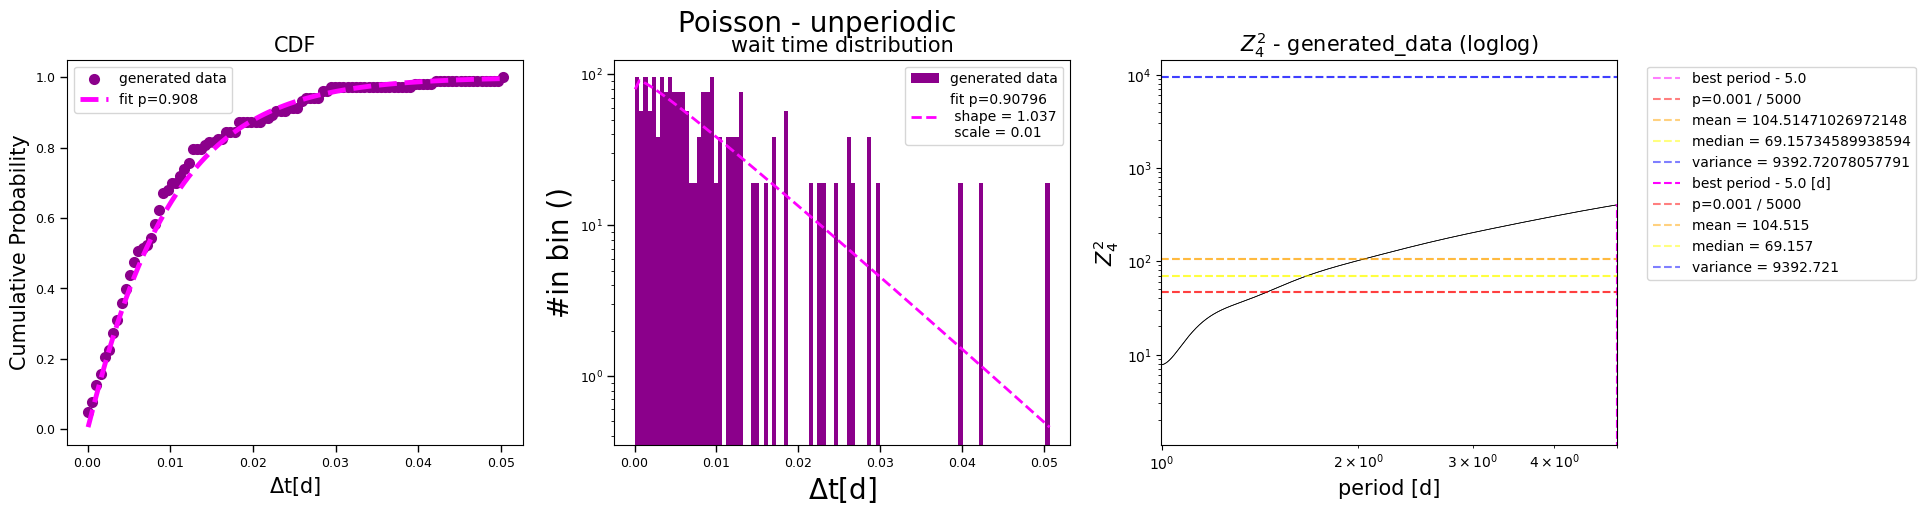

In [3]:
toas = generate_repeater_from_dist(1, dist = "poisson", rate = 100)
distribution_testing(toas, colors = ["darkmagenta", "magenta"], distribution = "Poisson - unperiodic", title = "Poisson_gen_unperiodic", saving = False)



<class 'numpy.ndarray'>
[0.01487531 0.03375676 0.04792615 0.05867352 0.06058986 0.07437492
 0.08502187 0.09900834 0.10340227 0.11630981 0.1279684  0.13843639
 0.15722663 0.16712826 0.17425852 0.18475454 0.19364801 0.20526838
 0.21696129 0.22894033 0.23692773 0.24624278 0.25908959 0.26887925
 0.2780022  0.28476622 0.29443482 0.30961368 0.3192399  0.32898189
 0.34549473 0.35408339 0.36108224 0.36303566 0.37474528 0.38459396
 0.39442528 0.40510765 0.42341904 0.43854183 0.44246514 0.45104433
 0.46174037 0.46818878 0.47708759 0.49326763 0.50262696 0.51365551
 0.51849306 0.53875588 0.54520148 0.54870543 0.5549184  0.57324743
 0.58117205 0.5843261  0.59827724 0.6072907  0.621704   0.63482086
 0.64545522 0.66129144 0.66385492 0.67782986 0.68762739 0.69867039
 0.70912305 0.72457342 0.7343043  0.74567099 0.75933228 0.76372023
 0.78139709 0.79061329 0.80673605 0.81622834 0.82288185 0.83375147
 0.83819252 0.84489775 0.85745728 0.86659817 0.87341338 0.87884324
 0.89584539 0.90496765 0.9076121  0.91

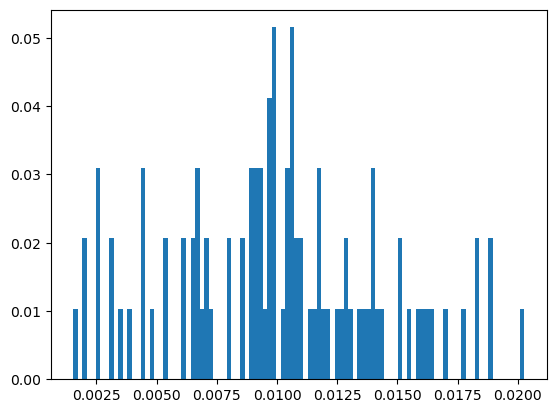

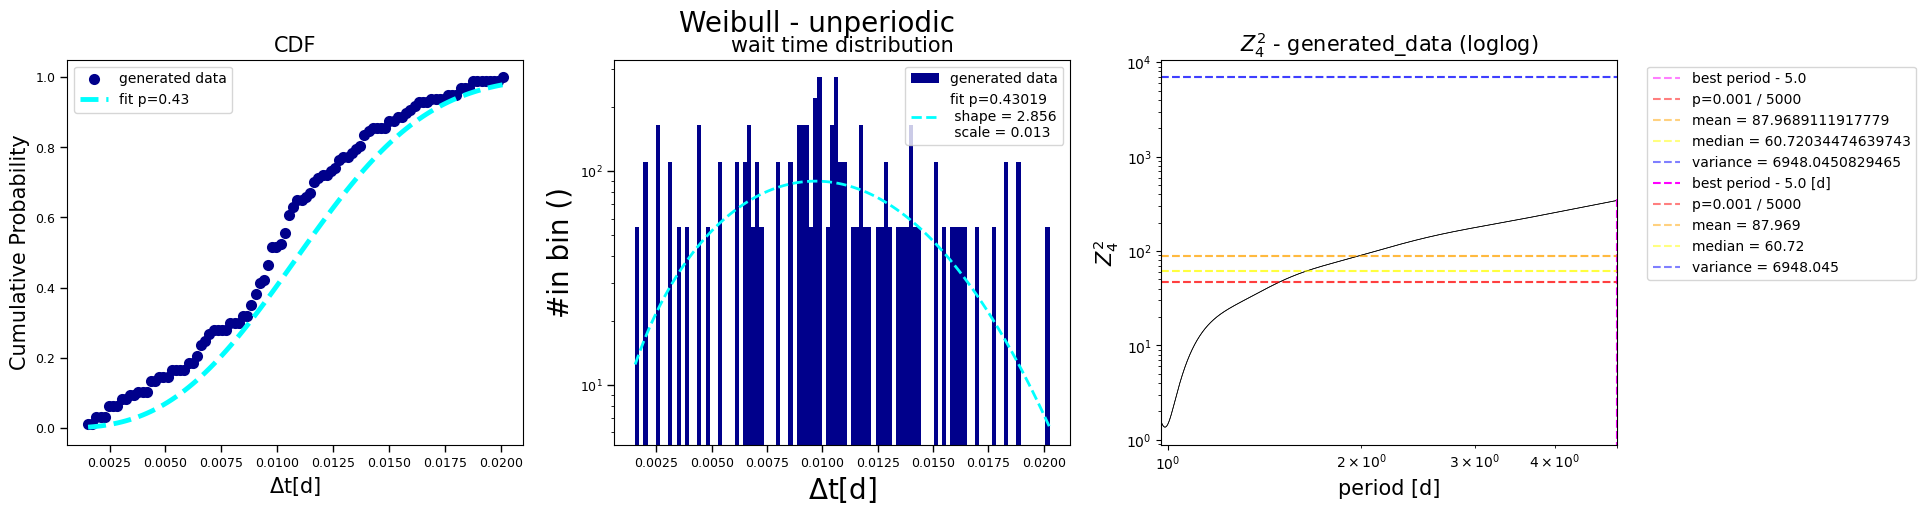

In [4]:

toas= generate_repeater_from_dist(1, dist = "weibull", shape = 2.5, mean_wait = 1/100)
distribution_testing(toas = toas, colors = ["darkblue", "cyan"], distribution = "Weibull - unperiodic", saving = False, title = "weibull_gen_unperiodic")


<class 'numpy.ndarray'>
[4.39781080e-03 1.00629855e+00 2.00029848e+00 ... 3.62230068e+04
 3.62350063e+04 3.62360035e+04]
0.2


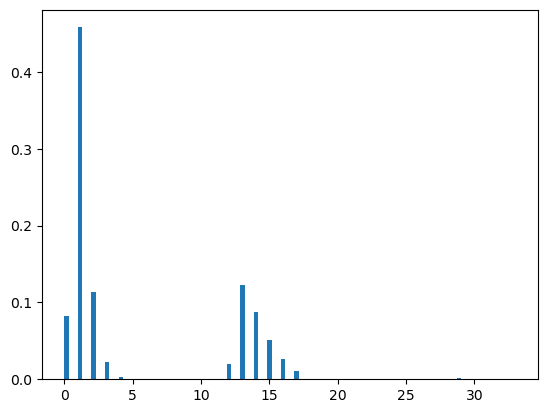

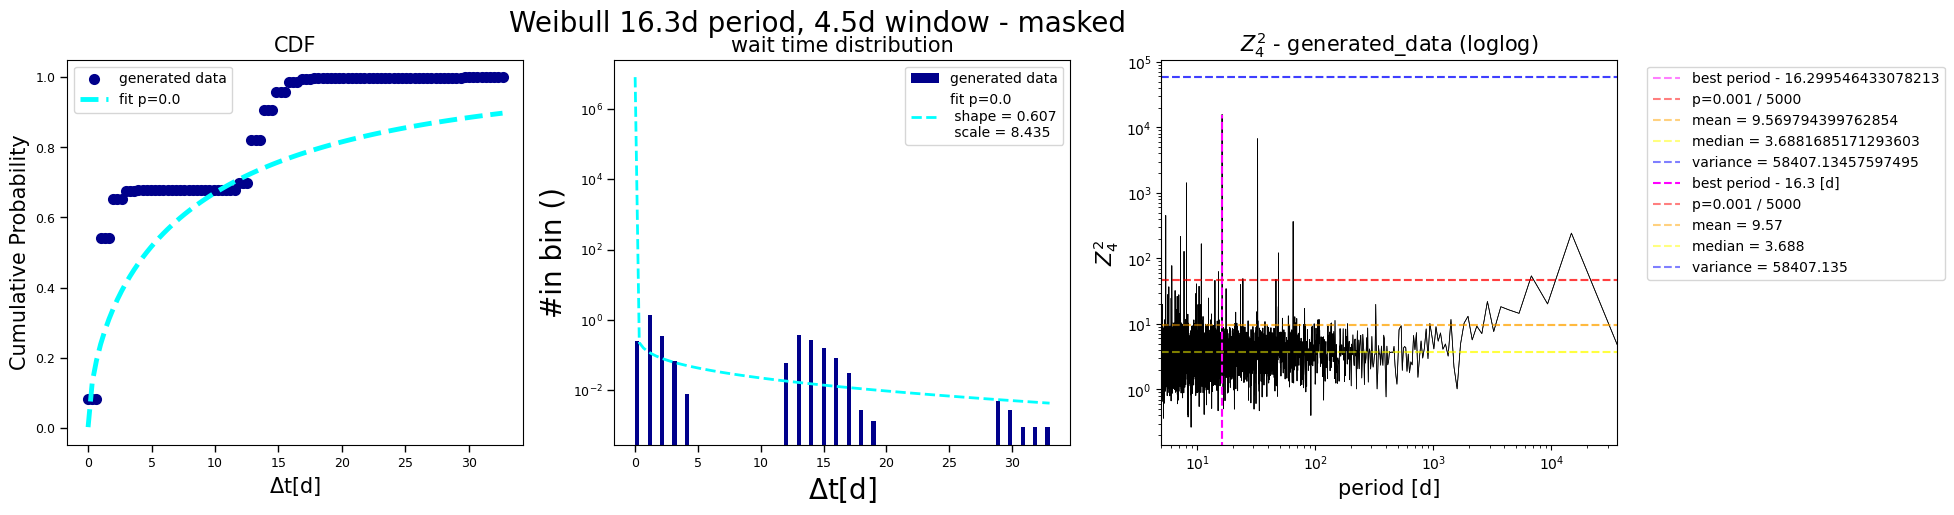

In [39]:
from generate_repeater import observing_window_mask

toas= generate_repeater_from_dist(1000000, dist = "weibull", shape = 2.5, mean_wait = 1/100, period = 16.3, window = 4.5)
toas = toas[observing_window_mask(toas)]
distribution_testing(toas = toas, colors = ["darkblue", "cyan"], distribution = "Weibull 16.3d period, 4.5d window - masked", saving = True, title = "weibull_gen_periodic_r3_masked")


<class 'numpy.ndarray'>
[1.00165892e+00 2.00478082e+00 1.70065650e+01 1.90001090e+01
 2.00061043e+01 2.00063299e+01 3.50035883e+01 3.70004000e+01
 3.70021580e+01 5.00006290e+01 5.00050327e+01 5.30017568e+01
 5.30024350e+01 6.60046306e+01 8.30010229e+01 8.40035215e+01
 8.50013118e+01 8.50020328e+01 9.80017791e+01 9.90008311e+01
 9.90051967e+01 1.01000684e+02 1.01002988e+02 1.16002818e+02
 1.17004987e+02 1.18002662e+02 1.18005648e+02 1.31002783e+02
 1.31003683e+02 1.31004204e+02 1.33006617e+02 1.34000845e+02
 1.34002036e+02 1.34004696e+02 1.47001677e+02 1.47004125e+02
 1.49002120e+02 1.49003625e+02 1.51000825e+02 1.63002820e+02
 1.63003179e+02 1.64000163e+02 1.67005738e+02 1.83005281e+02
 1.96000077e+02 1.97003745e+02 1.98005432e+02 1.99004052e+02
 2.16006547e+02 2.30003835e+02 2.45004067e+02 2.46002432e+02
 2.47000041e+02 2.47003864e+02 2.47004943e+02 2.47005598e+02
 2.48001548e+02 2.62003153e+02 2.81003067e+02 2.94002953e+02
 2.95001887e+02 2.97000410e+02 3.10002506e+02 3.14003978e+02


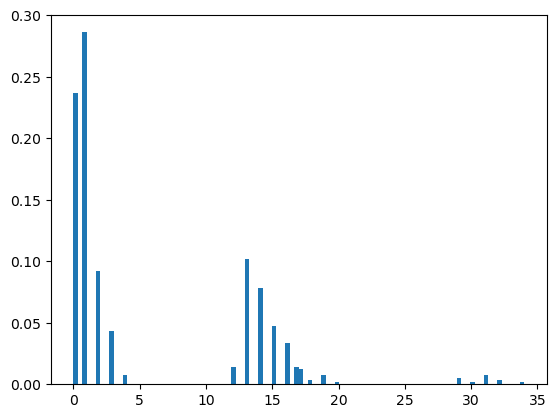

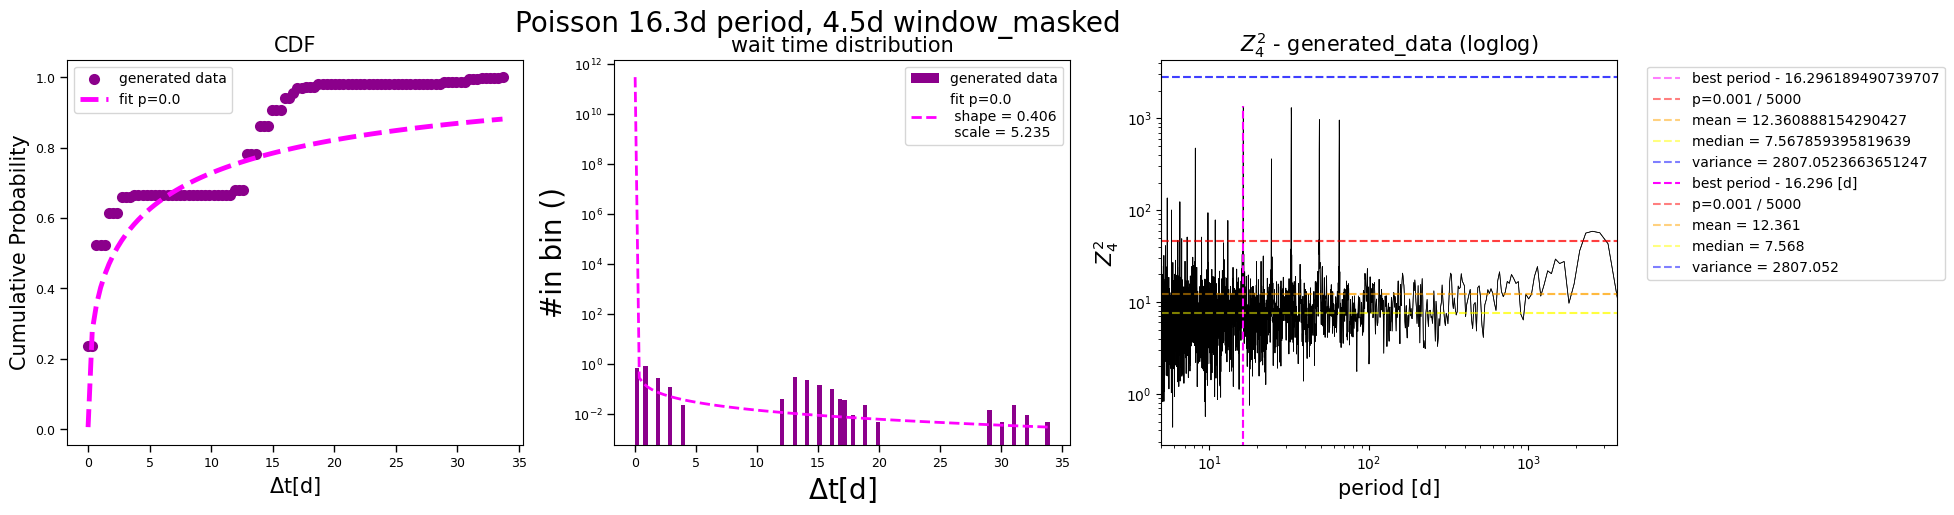

In [40]:
toas= generate_repeater_from_dist(100000, dist = "poisson", rate = 100, period = 16.3, window = 4.5)
toas = toas[observing_window_mask(toas)]
distribution_testing(toas = toas, colors = ["darkmagenta", "magenta"], distribution = "Poisson 16.3d period, 4.5d window_masked", saving = True, title = "poisson_gen_periodic_r3_mas")


<class 'numpy.ndarray'>
[6.65316045e-03 9.56411436e-03 1.39842814e-02 ... 3.61926020e+03
 3.61927111e+03 3.61928235e+03]
0.2


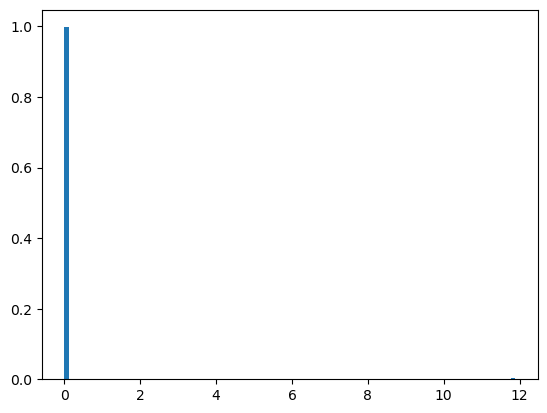

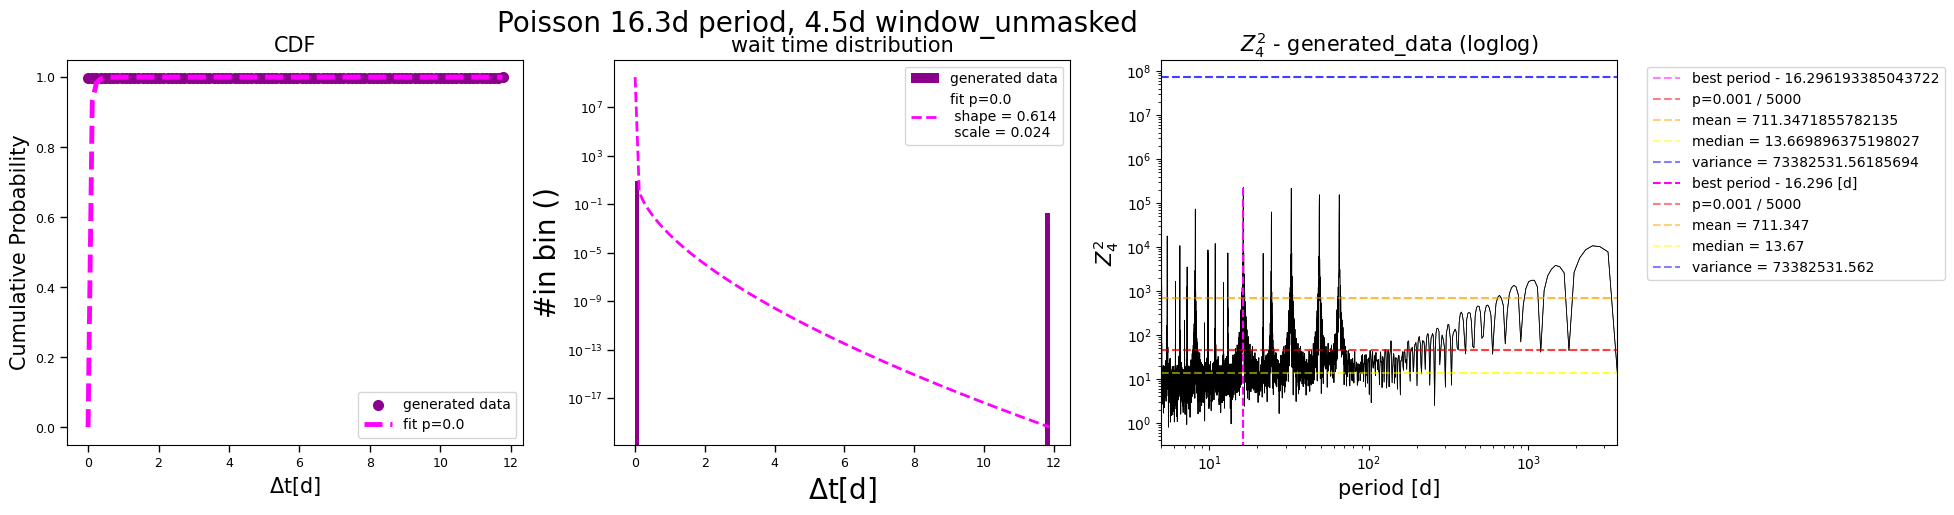

In [41]:
toas= generate_repeater_from_dist(100000, dist = "poisson", rate = 100, period = 16.3, window = 4.5)
distribution_testing(toas = toas, colors = ["darkmagenta", "magenta"], distribution = "Poisson 16.3d period, 4.5d window_unmasked", saving = True, title = "poisson_gen_periodic_r3_unmasked")


<class 'numpy.ndarray'>
[2.37522087e-03 1.73237490e-02 3.08231233e-02 ... 3.62055985e+03
 3.62056787e+03 3.62058171e+03]
0.2


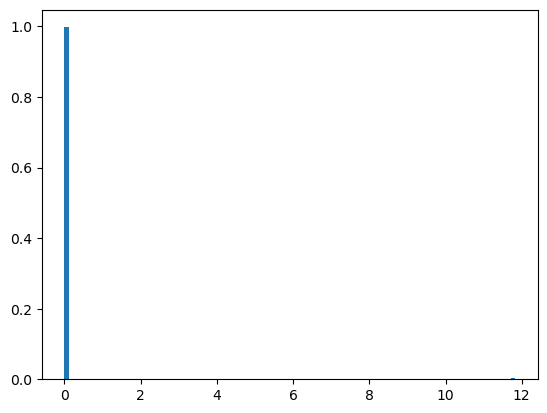

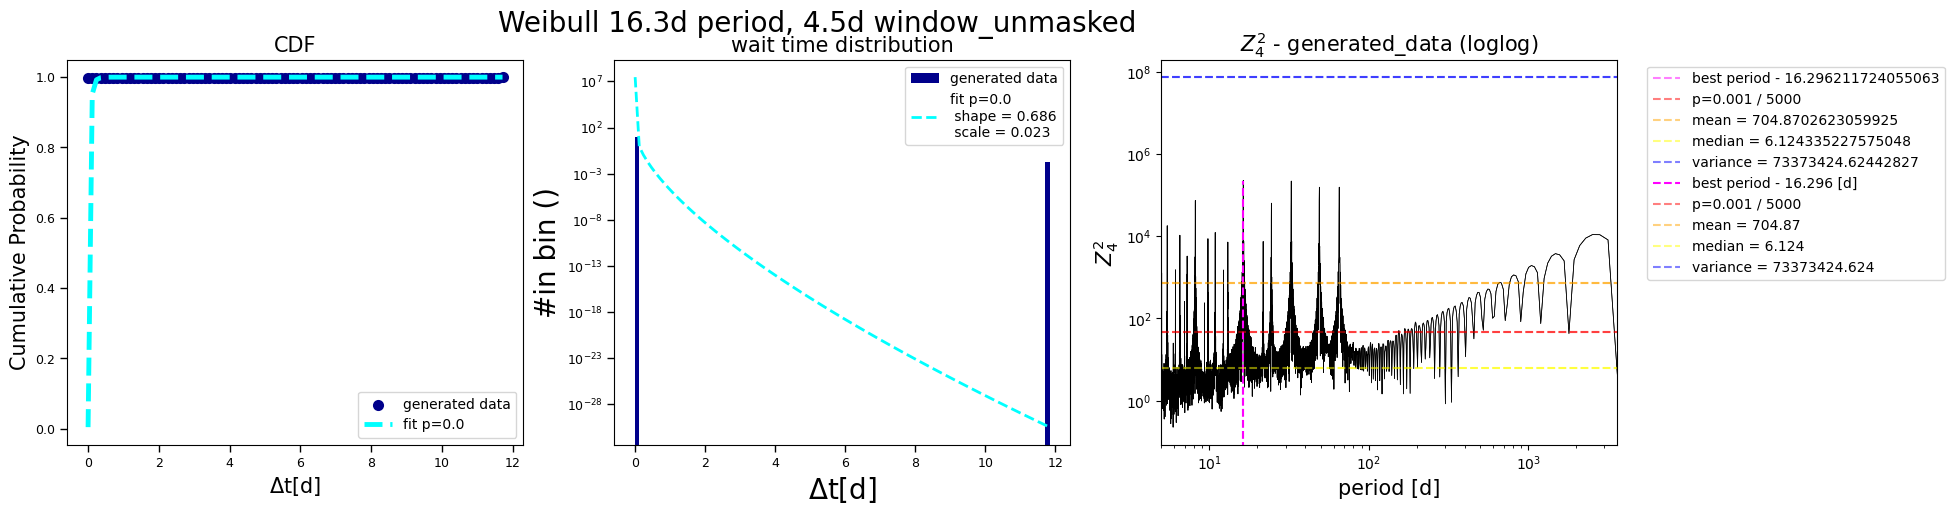

In [44]:
toas= generate_repeater_from_dist(100000, dist = "weibull", rate = 100,shape = 2.5, mean_wait = 1/100, period = 16.3, window = 4.5)
distribution_testing(toas = toas, colors = ["darkblue", "cyan"], distribution = "Weibull 16.3d period, 4.5d window_unmasked", saving = True, title = "weibull_gen_periodic_r3_unmasked")
